In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

PROJECT_PATH = "/content/drive/MyDrive/Ambulance_Allocation_System"

DATA_PATH = os.path.join(PROJECT_PATH, "data")
MODEL_PATH = os.path.join(PROJECT_PATH, "models")
RESULTS_PATH = os.path.join(PROJECT_PATH, "results")
APP_PATH = os.path.join(PROJECT_PATH, "app")

for folder in [PROJECT_PATH, DATA_PATH, MODEL_PATH, RESULTS_PATH, APP_PATH]:
    os.makedirs(folder, exist_ok=True)

print("Project folder:", PROJECT_PATH)
print("Data folder:", DATA_PATH)
print("Model folder:", MODEL_PATH)
print("Results folder:", RESULTS_PATH)
print("App folder:", APP_PATH)

Project folder: /content/drive/MyDrive/Ambulance_Allocation_System
Data folder: /content/drive/MyDrive/Ambulance_Allocation_System/data
Model folder: /content/drive/MyDrive/Ambulance_Allocation_System/models
Results folder: /content/drive/MyDrive/Ambulance_Allocation_System/results
App folder: /content/drive/MyDrive/Ambulance_Allocation_System/app


In [3]:
!pip install -q pandas numpy scikit-learn matplotlib seaborn folium gradio joblib openpyxl

In [4]:
import time
import math
import random
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
import gradio as gr

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [5]:
ISLAMABAD_LOCATIONS = {
    "F-6": (33.7294, 73.0931),
    "F-7": (33.7215, 73.0576),
    "F-8": (33.7080, 73.0430),
    "F-10": (33.6967, 73.0169),
    "F-11": (33.6880, 72.9870),
    "G-6": (33.7167, 73.0667),
    "G-7": (33.7065, 73.0650),
    "G-8": (33.6938, 73.0650),
    "G-9": (33.6895, 73.0350),
    "G-10": (33.6820, 73.0160),
    "G-11": (33.6685, 72.9980),
    "I-8": (33.6680, 73.0830),
    "I-9": (33.6550, 73.0670),
    "I-10": (33.6490, 73.0310),
    "Blue Area": (33.7167, 73.0700),
    "Bahria": (33.5520, 73.1160),
    "DHA": (33.5290, 73.1570),
    "Saddar": (33.5970, 73.0550)
}

EMERGENCY_TYPES = ["Accident", "Medical", "Fire", "Cardiac", "Trauma"]
SEVERITY_LEVELS = ["Low", "Medium", "High", "Critical"]
WEATHER_CONDITIONS = ["Clear", "Cloudy", "Rain"]

locations = list(ISLAMABAD_LOCATIONS.keys())

print("Islamabad locations:", len(locations))

Islamabad locations: 18


In [6]:
def calculate_distance(lat1, lon1, lat2, lon2):
    # Haversine distance estimates the straight-line distance between two coordinates.
    earth_radius_km = 6371.0

    lat1 = math.radians(lat1)
    lon1 = math.radians(lon1)
    lat2 = math.radians(lat2)
    lon2 = math.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        math.sin(dlat / 2) ** 2
        + math.cos(lat1)
        * math.cos(lat2)
        * math.sin(dlon / 2) ** 2
    )

    return earth_radius_km * 2 * math.atan2(
        math.sqrt(a),
        math.sqrt(1 - a)
    )

In [7]:
def simulate_response_time(
    distance_km,
    hour,
    traffic_level,
    severity,
    weather,
    emergency_type
):
    base_speed = 42.0

    if traffic_level >= 8:
        base_speed = 22.0
    elif traffic_level >= 5:
        base_speed = 30.0

    travel_time = (distance_km / base_speed) * 60

    peak_penalty = 2.5 if hour in [8, 9, 10, 17, 18, 19] else 0

    severity_penalty = {
        "Low": 0.0,
        "Medium": 1.0,
        "High": 2.5,
        "Critical": 4.0
    }[severity]

    weather_penalty = {
        "Clear": 0.0,
        "Cloudy": 0.8,
        "Rain": 3.0
    }[weather]

    emergency_penalty = {
        "Accident": 1.0,
        "Medical": 0.5,
        "Fire": 1.5,
        "Cardiac": 1.2,
        "Trauma": 1.0
    }[emergency_type]

    noise = np.random.normal(0, 1.5)

    return max(
        2.0,
        travel_time
        + peak_penalty
        + severity_penalty
        + weather_penalty
        + emergency_penalty
        + noise
    )


records = []

for emergency_id in range(1, 6001):

    emergency_location = random.choice(locations)
    ambulance_location = random.choice(locations)

    emergency_lat, emergency_lon = ISLAMABAD_LOCATIONS[emergency_location]
    ambulance_lat, ambulance_lon = ISLAMABAD_LOCATIONS[ambulance_location]

    distance_km = calculate_distance(
        emergency_lat,
        emergency_lon,
        ambulance_lat,
        ambulance_lon
    )

    timestamp = pd.Timestamp("2025-01-01") + pd.Timedelta(
        minutes=random.randint(0, 525599)
    )

    hour = timestamp.hour
    day_of_week = timestamp.dayofweek
    traffic_level = random.randint(1, 10)
    emergency_type = random.choice(EMERGENCY_TYPES)

    severity = random.choices(
        SEVERITY_LEVELS,
        weights=[15, 35, 35, 15]
    )[0]

    weather = random.choices(
        WEATHER_CONDITIONS,
        weights=[65, 25, 10]
    )[0]

    response_time = simulate_response_time(
        distance_km,
        hour,
        traffic_level,
        severity,
        weather,
        emergency_type
    )

    records.append({
        "emergency_id": emergency_id,
        "timestamp": timestamp,
        "hour": hour,
        "day_of_week": day_of_week,
        "emergency_location": emergency_location,
        "emergency_lat": emergency_lat,
        "emergency_lon": emergency_lon,
        "ambulance_location": ambulance_location,
        "ambulance_lat": ambulance_lat,
        "ambulance_lon": ambulance_lon,
        "distance_km": distance_km,
        "emergency_type": emergency_type,
        "severity": severity,
        "traffic_level": traffic_level,
        "weather": weather,
        "response_time": response_time
    })

df = pd.DataFrame(records)

raw_dataset_path = os.path.join(
    DATA_PATH,
    "islamabad_ambulance_synthetic_raw.csv"
)

df.to_csv(raw_dataset_path, index=False)

print("Dataset created.")
print("Rows:", len(df))
print("Columns:", len(df.columns))
df.head()

Dataset created.
Rows: 6000
Columns: 16


,emergency_id,timestamp,hour,day_of_week,emergency_location,emergency_lat,emergency_lon,ambulance_location,ambulance_lat,ambulance_lon,distance_km,emergency_type,severity,traffic_level,weather,response_time
0,1,2025-07-20 06:29:00,6,6,F-10,33.6967,73.0169,F-6,33.7294,73.0931,7.930765,Medical,Low,4,Clear,12.574736
1,2,2025-11-04 05:37:00,5,1,Saddar,33.5970,73.0550,F-8,33.7080,73.0430,12.392513,Accident,Low,1,Clear,18.496194
2,3,2025-05-25 18:56:00,18,6,F-6,33.7294,73.0931,Saddar,33.5970,73.0550,15.138587,Cardiac,Medium,9,Clear,46.958589
3,4,2025-11-04 17:43:00,17,1,F-6,33.7294,73.0931,G-6,33.7167,73.0667,2.820563,Fire,Medium,6,Rain,15.925670
4,5,2025-03-09 12:51:00,12,6,G-11,33.6685,72.9980,F-10,33.6967,73.0169,3.590378,Accident,Medium,7,Clear,8.829525


In [8]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().copy()

df["is_peak_hour"] = df["hour"].isin(
    [8, 9, 10, 17, 18, 19]
).astype(int)

df["is_weekend"] = (
    df["day_of_week"] >= 5
).astype(int)

df["month"] = df["timestamp"].dt.month

print("\nRows after cleaning:", len(df))

Missing values:
emergency_id          0
timestamp             0
hour                  0
day_of_week           0
emergency_location    0
emergency_lat         0
emergency_lon         0
ambulance_location    0
ambulance_lat         0
ambulance_lon         0
distance_km           0
emergency_type        0
severity              0
traffic_level         0
weather               0
response_time         0
dtype: int64

Duplicate rows: 0

Rows after cleaning: 6000


In [9]:
FEATURES = [
    "hour",
    "day_of_week",
    "emergency_lat",
    "emergency_lon",
    "ambulance_lat",
    "ambulance_lon",
    "distance_km",
    "traffic_level",
    "is_peak_hour",
    "is_weekend",
    "month",
    "emergency_type",
    "severity",
    "weather"
]

TARGET = "response_time"

X = df[FEATURES].copy()
y = df[TARGET].copy()

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

Training samples: 4200
Validation samples: 900
Test samples: 900


In [10]:
categorical_features = [
    "emergency_type",
    "severity",
    "weather"
]

numeric_features = [
    column for column in FEATURES
    if column not in categorical_features
]

def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            (
                "numeric",
                StandardScaler(),
                numeric_features
            ),
            (
                "categorical",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                ),
                categorical_features
            )
        ]
    )

models = {
    "KNN": KNeighborsRegressor(
        n_neighbors=7,
        weights="distance"
    ),
    "ANN": MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        alpha=0.0005,
        learning_rate_init=0.001,
        max_iter=500,
        early_stopping=True,
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=250,
        max_depth=16,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

pipelines = {
    name: Pipeline(
        steps=[
            ("preprocessor", make_preprocessor()),
            ("model", model)
        ]
    )
    for name, model in models.items()
}

print("Models:", list(pipelines.keys()))

Models: ['KNN', 'ANN', 'Random Forest']


In [11]:
def calculate_metrics(actual, predicted):
    mse = mean_squared_error(actual, predicted)

    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mse),
        "R2": r2_score(actual, predicted)
    }


validation_results = []
trained_models = {}

for model_name, pipeline in pipelines.items():

    print(f"Training {model_name}...")

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_val)

    metrics = calculate_metrics(
        y_val,
        predictions
    )

    validation_results.append({
        "Model": model_name,
        **metrics
    })

    trained_models[model_name] = pipeline

validation_df = pd.DataFrame(
    validation_results
).sort_values("RMSE").reset_index(drop=True)

print("\nValidation Results")
display(validation_df.round(3))

Training KNN...
Training ANN...
Training Random Forest...

Validation Results


,Model,MAE,RMSE,R2
0,Random Forest,1.466,1.862,0.983
1,ANN,1.681,2.214,0.976
2,KNN,3.723,4.945,0.881


In [12]:
best_model_name = validation_df.iloc[0]["Model"]

X_train_final = pd.concat(
    [X_train, X_val],
    ignore_index=True
)

y_train_final = pd.concat(
    [y_train, y_val],
    ignore_index=True
)

best_model = pipelines[best_model_name]

best_model.fit(
    X_train_final,
    y_train_final
)

final_results = []

for model_name in models:

    if model_name == best_model_name:
        model_pipeline = best_model
    else:
        model_pipeline = trained_models[model_name]
        model_pipeline.fit(
            X_train_final,
            y_train_final
        )

    predictions = model_pipeline.predict(X_test)

    final_results.append({
        "Model": model_name,
        **calculate_metrics(y_test, predictions)
    })

final_results_df = pd.DataFrame(
    final_results
).sort_values("RMSE").reset_index(drop=True)

test_predictions = best_model.predict(X_test)

print("Selected model:", best_model_name)
display(final_results_df.round(3))

final_results_df.to_csv(
    os.path.join(
        RESULTS_PATH,
        "model_comparison_test_results.csv"
    ),
    index=False
)

Selected model: Random Forest


,Model,MAE,RMSE,R2
0,Random Forest,1.450,1.824,0.981
1,ANN,1.641,2.116,0.975
2,KNN,3.576,4.771,0.873


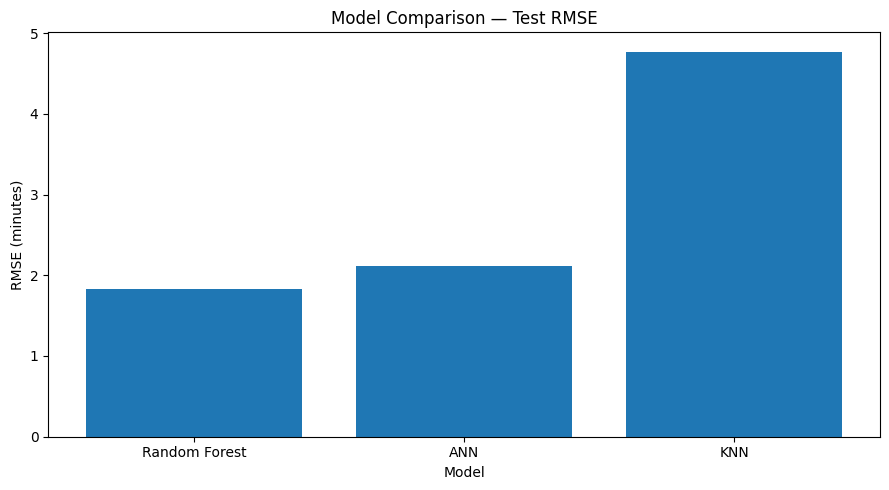

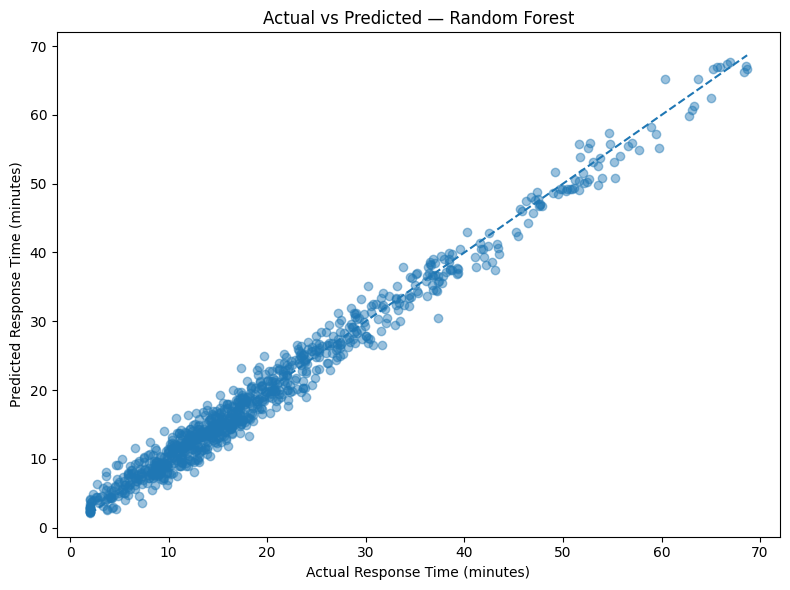

In [13]:
plt.figure(figsize=(9, 5))

plt.bar(
    final_results_df["Model"],
    final_results_df["RMSE"]
)

plt.title("Model Comparison — Test RMSE")
plt.xlabel("Model")
plt.ylabel("RMSE (minutes)")
plt.tight_layout()

plt.savefig(
    os.path.join(
        RESULTS_PATH,
        "model_comparison_rmse.png"
    ),
    dpi=200,
    bbox_inches="tight"
)

plt.show()


plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    test_predictions,
    alpha=0.45
)

minimum = min(
    y_test.min(),
    test_predictions.min()
)

maximum = max(
    y_test.max(),
    test_predictions.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Response Time (minutes)")
plt.ylabel("Predicted Response Time (minutes)")
plt.title(f"Actual vs Predicted — {best_model_name}")
plt.tight_layout()

plt.savefig(
    os.path.join(
        RESULTS_PATH,
        "actual_vs_predicted.png"
    ),
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [14]:
joblib.dump(
    best_model,
    os.path.join(
        MODEL_PATH,
        "best_response_time_model.pkl"
    )
)

print("Best model:", best_model_name)
print(
    "Saved to:",
    os.path.join(
        MODEL_PATH,
        "best_response_time_model.pkl"
    )
)

Best model: Random Forest
Saved to: /content/drive/MyDrive/Ambulance_Allocation_System/models/best_response_time_model.pkl


In [15]:
ambulances = pd.DataFrame({
    "ambulance_id": [
        "A-01", "A-02", "A-03", "A-04",
        "A-05", "A-06", "A-07", "A-08"
    ],
    "location": [
        "F-6", "F-8", "G-9", "G-11",
        "I-8", "G-6", "Saddar", "Bahria"
    ],
    "available": [1] * 8
})

fleet_state = ambulances.copy()

display(fleet_state)

,ambulance_id,location,available
0,A-01,F-6,1
1,A-02,F-8,1
2,A-03,G-9,1
3,A-04,G-11,1
4,A-05,I-8,1
5,A-06,G-6,1
6,A-07,Saddar,1
7,A-08,Bahria,1


In [17]:
def build_candidate_features(
    emergency_location,
    emergency_type,
    severity,
    traffic_level,
    weather
):
    emergency_lat, emergency_lon = ISLAMABAD_LOCATIONS[
        emergency_location
    ]

    current_time = pd.Timestamp.now()

    candidates = []

    for _, ambulance in fleet_state[
        fleet_state["available"] == 1
    ].iterrows():

        ambulance_lat, ambulance_lon = ISLAMABAD_LOCATIONS[
            ambulance["location"]
        ]

        distance_km = calculate_distance(
            emergency_lat,
            emergency_lon,
            ambulance_lat,
            ambulance_lon
        )

        candidates.append({
            "ambulance_id": ambulance["ambulance_id"],
            "ambulance_location": ambulance["location"],
            "hour": current_time.hour,
            "day_of_week": current_time.dayofweek,
            "emergency_lat": emergency_lat,
            "emergency_lon": emergency_lon,
            "ambulance_lat": ambulance_lat,
            "ambulance_lon": ambulance_lon,
            "distance_km": distance_km,
            "traffic_level": traffic_level,
            "is_peak_hour": int(
                current_time.hour in [8, 9, 10, 17, 18, 19]
            ),
            "is_weekend": int(
                current_time.dayofweek >= 5
            ),
            "month": current_time.month,
            "emergency_type": emergency_type,
            "severity": severity,
            "weather": weather
        })

    return pd.DataFrame(candidates)


def allocate_ambulance(
    emergency_location,
    emergency_type,
    severity,
    traffic_level,
    weather
):
    candidates = build_candidate_features(
        emergency_location,
        emergency_type,
        severity,
        traffic_level,
        weather
    )

    if candidates.empty:
        return None

    candidates["predicted_response_time"] = best_model.predict(
        candidates[FEATURES]
    )

    # Lower predicted response time is preferred; distance provides a small
    # secondary preference when two candidates are otherwise similar.
    candidates["allocation_score"] = (
        candidates["predicted_response_time"]
        + 0.20 * candidates["distance_km"]
    )

    return candidates.sort_values(
        "allocation_score"
    ).reset_index(drop=True)

In [18]:
allocation_result = allocate_ambulance(
    emergency_location="F-8",
    emergency_type="Accident",
    severity="Critical",
    traffic_level=8,
    weather="Clear"
)

display(
    allocation_result[
        [
            "ambulance_id",
            "ambulance_location",
            "distance_km",
            "predicted_response_time",
            "allocation_score"
        ]
    ].round(2)
)

,ambulance_id,ambulance_location,distance_km,predicted_response_time,allocation_score
0,A-02,F-8,0.00,6.27,6.27
1,A-03,G-9,2.19,10.93,11.37
2,A-06,G-6,2.40,10.99,11.47
3,A-01,F-6,5.21,19.56,20.61
4,A-05,I-8,5.79,19.97,21.13
5,A-04,G-11,6.05,21.23,22.44
6,A-07,Saddar,12.39,40.01,42.49
7,A-08,Bahria,18.62,54.26,57.98


In [19]:
def evaluate_dispatch_baseline(number_of_scenarios=200):

    rows = []

    available_locations = list(
        fleet_state["location"]
    )

    for _ in range(number_of_scenarios):

        emergency_location = random.choice(locations)
        emergency_type = random.choice(EMERGENCY_TYPES)
        severity = random.choice(SEVERITY_LEVELS)
        traffic_level = random.randint(1, 10)
        weather = random.choice(WEATHER_CONDITIONS)

        emergency_lat, emergency_lon = ISLAMABAD_LOCATIONS[
            emergency_location
        ]

        candidate_rows = []

        for ambulance_location in available_locations:

            ambulance_lat, ambulance_lon = ISLAMABAD_LOCATIONS[
                ambulance_location
            ]

            distance = calculate_distance(
                emergency_lat,
                emergency_lon,
                ambulance_lat,
                ambulance_lon
            )

            candidate_rows.append({
                "location": ambulance_location,
                "distance": distance
            })

        nearest = min(
            candidate_rows,
            key=lambda row: row["distance"]
        )

        ai_candidates = allocate_ambulance(
            emergency_location,
            emergency_type,
            severity,
            traffic_level,
            weather
        )

        ai_selected = ai_candidates.iloc[0]

        ai_distance = float(
            ai_selected["distance_km"]
        )

        nearest_actual_time = simulate_response_time(
            nearest["distance"],
            pd.Timestamp.now().hour,
            traffic_level,
            severity,
            weather,
            emergency_type
        )

        ai_actual_time = simulate_response_time(
            ai_distance,
            pd.Timestamp.now().hour,
            traffic_level,
            severity,
            weather,
            emergency_type
        )

        rows.append({
            "Nearest Ambulance Response": nearest_actual_time,
            "AI Allocation Response": ai_actual_time
        })

    evaluation = pd.DataFrame(rows)

    summary = pd.DataFrame({
        "Method": [
            "Nearest Ambulance",
            "AI Allocation"
        ],
        "Average Response Time (min)": [
            evaluation["Nearest Ambulance Response"].mean(),
            evaluation["AI Allocation Response"].mean()
        ]
    })

    return summary


baseline_results = evaluate_dispatch_baseline()

display(
    baseline_results.round(2)
)

baseline_results.to_csv(
    os.path.join(
        RESULTS_PATH,
        "baseline_comparison.csv"
    ),
    index=False
)

,Method,Average Response Time (min)
0,Nearest Ambulance,7.00
1,AI Allocation,6.82


In [20]:
def create_tracking_map(
    emergency_location,
    ambulance_id,
    progress,
    status
):
    emergency_lat, emergency_lon = ISLAMABAD_LOCATIONS[
        emergency_location
    ]

    selected = fleet_state[
        fleet_state["ambulance_id"] == ambulance_id
    ]

    if selected.empty:
        return "<p>Ambulance not found.</p>"

    ambulance_location = selected.iloc[0]["location"]

    ambulance_lat, ambulance_lon = ISLAMABAD_LOCATIONS[
        ambulance_location
    ]

    progress = max(
        0.0,
        min(1.0, progress)
    )

    current_lat = (
        ambulance_lat
        + (emergency_lat - ambulance_lat) * progress
    )

    current_lon = (
        ambulance_lon
        + (emergency_lon - ambulance_lon) * progress
    )

    remaining_distance = calculate_distance(
        current_lat,
        current_lon,
        emergency_lat,
        emergency_lon
    )

    m = folium.Map(
        location=[
            (current_lat + emergency_lat) / 2,
            (current_lon + emergency_lon) / 2
        ],
        zoom_start=12,
        tiles="OpenStreetMap"
    )

    folium.Marker(
        [emergency_lat, emergency_lon],
        tooltip="🚨 Emergency",
        popup=f"<b>Emergency</b><br>{emergency_location}",
        icon=folium.DivIcon(
            html="""
            <div style="font-size:30px;text-align:center;
                        transform:translate(-50%,-50%);">
                🚨
            </div>
            """
        )
    ).add_to(m)

    folium.Marker(
        [current_lat, current_lon],
        tooltip=f"🚑 {ambulance_id}",
        popup=f"""
        <b>🚑 {ambulance_id}</b><br>
        Status: {status}<br>
        Progress: {progress * 100:.0f}%<br>
        Remaining: {remaining_distance:.2f} km
        """,
        icon=folium.DivIcon(
            html="""
            <div style="font-size:30px;text-align:center;
                        transform:translate(-50%,-50%);">
                🚑
            </div>
            """
        )
    ).add_to(m)

    folium.PolyLine(
        [
            [ambulance_lat, ambulance_lon],
            [emergency_lat, emergency_lon]
        ],
        color="red",
        weight=5,
        opacity=0.75
    ).add_to(m)

    return m._repr_html_()

In [35]:
# ============================================================
# ISLAMABAD AMBULANCE COMMAND CENTER
# Redesigned Gradio Interface
# ============================================================

import gradio as gr
import pandas as pd
import time


# -------------------- HELPER FUNCTIONS --------------------

def format_timer(seconds):
    seconds = max(0, int(seconds))
    minutes = seconds // 60
    remaining_seconds = seconds % 60
    return f"{minutes:02d}:{remaining_seconds:02d}"


def get_fleet_display():
    display_df = fleet_state.copy()

    display_df["Status"] = display_df["available"].map({
        1: "🟢 Available",
        0: "🟠 Busy"
    })

    return display_df[
        ["ambulance_id", "location", "Status"]
    ].rename(columns={
        "ambulance_id": "Ambulance ID",
        "location": "Current Location"
    })


def get_fleet_stats():
    total = len(fleet_state)
    available = int(fleet_state["available"].sum())
    busy = total - available

    return f"""
    <div class="stats-container">

        <div class="stat-card">
            <div class="stat-icon blue">🚑</div>
            <div class="stat-number">{total}</div>
            <div class="stat-label">TOTAL AMBULANCES</div>
        </div>

        <div class="stat-card">
            <div class="stat-icon green">✓</div>
            <div class="stat-number green-text">{available}</div>
            <div class="stat-label">AVAILABLE</div>
        </div>

        <div class="stat-card">
            <div class="stat-icon orange">↗</div>
            <div class="stat-number orange-text">{busy}</div>
            <div class="stat-label">BUSY / DISPATCHED</div>
        </div>

    </div>
    """


def get_progress_html(progress):
    percentage = min(100, max(0, int(progress * 100)))

    return f"""
    <div class="progress-container">
        <div class="progress-heading">
            <span>Journey Progress</span>
            <strong>{percentage}%</strong>
        </div>
        <div class="progress-track">
            <div class="progress-fill" style="width:{percentage}%"></div>
        </div>
    </div>
    """


def get_priority_label(severity):
    return {
        "Critical": "🔴 CRITICAL",
        "High": "🟠 HIGH",
        "Medium": "🟡 MEDIUM",
        "Low": "🟢 LOW"
    }.get(severity, severity)


def get_candidate_display(result):
    if result is None or result.empty:
        return pd.DataFrame(columns=[
            "Ambulance",
            "Location",
            "Distance (km)",
            "Predicted ETA (min)",
            "AI Score"
        ])

    display = result[
        [
            "ambulance_id",
            "ambulance_location",
            "distance_km",
            "predicted_response_time",
            "allocation_score"
        ]
    ].copy()

    display.columns = [
        "Ambulance",
        "Location",
        "Distance (km)",
        "Predicted ETA (min)",
        "AI Score"
    ]

    return display.round(2)


# -------------------- DISPATCH FUNCTION --------------------

def dispatch_request(
    emergency_location,
    emergency_type,
    severity,
    traffic,
    weather,
    current_tracking
):
    global fleet_state

    # Prevent accidental overlapping dispatches in this demo.
    if current_tracking and current_tracking.get("active"):
        return (
            "🟠 DISPATCH ALREADY ACTIVE",
            current_tracking["ambulance_id"],
            "An active dispatch is in progress.",
            "N/A", "N/A",
            get_fleet_display(),
            get_fleet_stats(),
            gr.update(),
            current_tracking,
            "An ambulance is already responding to an emergency.",
            gr.update(),
            gr.update(),
            gr.update(),
            gr.update()
        )

    result = allocate_ambulance(
        emergency_location,
        emergency_type,
        severity,
        int(traffic),
        weather
    )

    if result is None or result.empty:
        return (
            "🔴 NO AMBULANCE AVAILABLE",
            "None",
            get_priority_label(severity),
            "N/A",
            "N/A",
            get_fleet_display(),
            get_fleet_stats(),
            create_tracking_map(
                emergency_location,
                "A-01",
                0,
                "NO AVAILABLE AMBULANCE"
            ),
            None,
            f"""
### No ambulance available

**Emergency location:** {emergency_location}

The system could not find an available ambulance.
Please check fleet availability.
""",
            "00:00",
            "Waiting",
            get_progress_html(0),
            get_candidate_display(result)
        )

    best = result.iloc[0]

    ambulance_id = best["ambulance_id"]
    ambulance_location = best["ambulance_location"]
    predicted_eta = float(best["predicted_response_time"])
    distance = float(best["distance_km"])

    selected_index = fleet_state.index[
        fleet_state["ambulance_id"] == ambulance_id
    ][0]

    fleet_state.loc[selected_index, "available"] = 0

    # One-minute demonstration journey.
    demo_duration = 60

    tracking_state = {
        "active": True,
        "ambulance_id": ambulance_id,
        "emergency_location": emergency_location,
        "start_time": time.time(),
        "duration": demo_duration,
        "total_distance": distance,
        "predicted_eta": predicted_eta
    }

    timeline = f"""
### 📡 Dispatch Timeline

<text>Emergency received</text>

🟢 **Emergency registered**

📍 Location: {emergency_location}

↓

🧠 **AI allocation completed**

🚑 Selected ambulance: {ambulance_id}

↓

🟠 **Ambulance dispatched**

📍 Starting location: {ambulance_location}

↓

🚑 **EN ROUTE**

⏱️ AI predicted response time: {predicted_eta:.2f} minutes
"""

    return (
        "🟠 AMBULANCE DISPATCHED",
        f"🚑 {ambulance_id}",
        get_priority_label(severity),
        f"{distance:.2f} km",
        f"{predicted_eta:.2f} min",
        get_fleet_display(),
        get_fleet_stats(),
        create_tracking_map(
            emergency_location,
            ambulance_id,
            0,
            "DISPATCHED"
        ),
        tracking_state,
        timeline,
        format_timer(demo_duration),
        f"{distance:.2f} km",
        get_progress_html(0),
        get_candidate_display(result)
    )


# -------------------- LIVE TRACKING --------------------

def update_tracking(tracking_state):
    global fleet_state

    if not tracking_state or not tracking_state.get("active"):
        return (
            gr.update(),
            "🟢 SYSTEM READY",
            "00:00",
            "Waiting for dispatch",
            get_progress_html(0),
            get_fleet_display(),
            get_fleet_stats(),
            tracking_state,
            gr.update()
        )

    elapsed = time.time() - tracking_state["start_time"]
    duration = tracking_state["duration"]

    progress = min(elapsed / duration, 1.0)

    remaining_seconds = max(0, duration - elapsed)

    ambulance_id = tracking_state["ambulance_id"]
    emergency_location = tracking_state["emergency_location"]

    remaining_distance = (
        tracking_state["total_distance"] * (1 - progress)
    )

    if progress >= 1:

        status = "🟢 ARRIVED"

        selected_index = fleet_state.index[
            fleet_state["ambulance_id"] == ambulance_id
        ][0]

        fleet_state.loc[selected_index, "available"] = 1

        tracking_state["active"] = False

        timeline = f"""
### 📡 Dispatch Completed

🟢 Emergency received

↓

🧠 AI allocation completed

↓

🚑 **{ambulance_id} dispatched**

↓

🟠 EN ROUTE

↓

🟢 **ARRIVED AT {emergency_location}**

**The simulated demonstration journey is complete.**
"""

        remaining_distance = 0

    elif progress >= 0.85:

        status = "🟡 ARRIVING"

        timeline = f"""
### 📡 Live Dispatch Status

🚑 **{ambulance_id} — ARRIVING**

📍 Destination: {emergency_location}

📊 Journey completed: **{progress * 100:.0f}%**

📏 Remaining distance: **{remaining_distance:.2f} km**
"""

    else:

        status = "🟠 EN ROUTE"

        timeline = f"""
### 📡 Live Dispatch Status

🚑 **{ambulance_id} — EN ROUTE**

📍 Destination: {emergency_location}

📊 Journey completed: **{progress * 100:.0f}%**

📏 Remaining distance: **{remaining_distance:.2f} km**
"""

    map_html = create_tracking_map(
        emergency_location,
        ambulance_id,
        progress,
        status
    )

    return (
        map_html,
        status,
        format_timer(remaining_seconds),
        f"{remaining_distance:.2f} km",
        get_progress_html(progress),
        get_fleet_display(),
        get_fleet_stats(),
        tracking_state,
        timeline
    )


# -------------------- RESET FUNCTION --------------------

def reset_system():
    global fleet_state

    fleet_state["available"] = 1

    return (
        "🟢 SYSTEM READY",
        "No ambulance dispatched",
        "Awaiting emergency",
        "N/A",
        "N/A",
        get_fleet_display(),
        get_fleet_stats(),
        create_tracking_map(
            "F-8",
            "A-01",
            0,
            "AVAILABLE"
        ),
        None,
        """
### 📡 Dispatch Timeline

System reset successfully.

Waiting for a new emergency request.
""",
        "00:00",
        "Waiting",
        get_progress_html(0),
        get_candidate_display(None)
    )


# ============================================================
# PROFESSIONAL DASHBOARD CSS
# ============================================================

css = """
@import url('https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700;800&display=swap');

.gradio-container {
    max-width: 1500px !important;
    margin: auto !important;
    font-family: 'Inter', sans-serif !important;
    background: #F3F6FA !important;
}

body {
    background: #F3F6FA !important;
}

/* Header */

.dashboard-header {
    background: linear-gradient(120deg, #142B45, #203F60);
    padding: 27px 32px;
    border-radius: 15px;
    color: white;
    margin-bottom: 20px;
    border-bottom: 4px solid #D93636;
}

.header-title {
    font-size: 29px;
    font-weight: 800;
    letter-spacing: -0.7px;
}

.header-subtitle {
    color: #C8D5E3;
    font-size: 13px;
    margin-top: 7px;
}

.header-status {
    background: #174D3A;
    color: #A7F3C5;
    padding: 7px 13px;
    border-radius: 20px;
    font-size: 11px;
    font-weight: 700;
}

/* Section headings */

.section-heading {
    color: #142B45;
    font-size: 19px;
    font-weight: 800;
    margin: 8px 0 12px 0;
}

/* Cards */

.panel {
    background: white;
    border: 1px solid #E2E8F0;
    border-radius: 13px;
    padding: 19px;
    box-shadow: 0 3px 12px rgba(25, 45, 70, 0.04);
}

/* Statistics */

.stats-container {
    display: grid;
    grid-template-columns: repeat(3, 1fr);
    gap: 14px;
    margin-bottom: 18px;
}

.stat-card {
    background: white;
    border: 1px solid #E3E9F0;
    border-radius: 12px;
    padding: 17px;
    min-height: 115px;
}

.stat-icon {
    width: 32px;
    height: 32px;
    border-radius: 9px;
    display: flex;
    justify-content: center;
    align-items: center;
    font-size: 17px;
}

.blue {
    background: #E7F0FC;
    color: #2863A8;
}

.green {
    background: #E5F6ED;
    color: #188653;
}

.orange {
    background: #FFF0DF;
    color: #D47B20;
}

.stat-number {
    font-size: 29px;
    font-weight: 800;
    color: #142B45;
    margin-top: 7px;
}

.green-text {
    color: #188653;
}

.orange-text {
    color: #D47B20;
}

.stat-label {
    font-size: 10px;
    font-weight: 700;
    color: #718096;
    letter-spacing: 0.5px;
    margin-top: 3px;
}

/* Buttons */

.dispatch-button {
    min-height: 55px !important;
    background: #D93636 !important;
    color: white !important;
    border: none !important;
    font-weight: 800 !important;
    font-size: 15px !important;
    border-radius: 9px !important;
    transition: 0.2s ease !important;
}

.dispatch-button:hover {
    background: #B92727 !important;
}

.reset-button {
    min-height: 43px !important;
    border-radius: 9px !important;
}

/* Input fields */

label {
    color: #34465B !important;
    font-weight: 600 !important;
}

input, textarea {
    border-radius: 8px !important;
}

/* Tracking */

.timer-box input {
    font-size: 35px !important;
    font-weight: 800 !important;
    color: #D93636 !important;
    text-align: center !important;
    background: #FFF5F5 !important;
    border: 1px solid #F5D3D3 !important;
}

.progress-container {
    background: white;
    padding: 15px;
    border: 1px solid #E3E9F0;
    border-radius: 11px;
    margin-top: 12px;
}

.progress-heading {
    display: flex;
    justify-content: space-between;
    color: #34465B;
    font-size: 13px;
    margin-bottom: 10px;
}

.progress-heading strong {
    color: #D93636;
}

.progress-track {
    height: 11px;
    background: #E8EDF3;
    border-radius: 20px;
    overflow: hidden;
}

.progress-fill {
    height: 100%;
    background: linear-gradient(90deg, #D93636, #F07858);
    border-radius: 20px;
    transition: width 0.5s ease;
}

/* Tables */

table {
    border-radius: 8px !important;
}

/* Timeline */

.timeline-panel {
    background: white;
    border: 1px solid #E2E8F0;
    border-left: 4px solid #D93636;
    padding: 20px;
    border-radius: 10px;
}

/* Footer */

.footer {
    text-align: center;
    color: #718096;
    font-size: 11px;
    padding: 20px;
    border-top: 1px solid #E2E8F0;
    margin-top: 20px;
}

@media(max-width: 768px) {
    .dashboard-header {
        padding: 20px;
    }

    .header-title {
        font-size: 21px;
    }

    .stats-container {
        grid-template-columns: 1fr;
    }
}
"""


# ============================================================
# GRADIO APPLICATION
# ============================================================

with gr.Blocks(
    title="Ambulance Allocation System",
    theme=gr.themes.Soft(
        primary_hue="red",
        secondary_hue="blue",
        neutral_hue="slate"
    ),
    css=css
) as app:

    tracking_state = gr.State(None)

    # HEADER

    gr.HTML("""
    <div class="dashboard-header">
        <div style="display:flex; justify-content:space-between;
                    align-items:center; flex-wrap:wrap; gap:15px;">

            <div>
                <div class="header-title">
                    🚑 Islamabad Ambulance Command Center
                </div>

                <div class="header-subtitle">
                    AI-Powered Emergency Response, Intelligent Allocation
                    & Simulated Live Tracking
                </div>
            </div>

            <div class="header-status">
                ● SYSTEM ONLINE
            </div>

        </div>
    </div>
    """)

    # FLEET STATISTICS

    gr.HTML('<div class="section-heading">📊 Fleet Overview</div>')

    fleet_stats = gr.HTML(value=get_fleet_stats())

    # MAIN DASHBOARD

    with gr.Row(equal_height=False):

        # LEFT: EMERGENCY FORM

        with gr.Column(scale=1, min_width=290):

            with gr.Group(elem_classes="panel"):

                gr.Markdown("## 🚨 Emergency Request")

                gr.Markdown(
                    "Enter the emergency details to initiate "
                    "AI-based ambulance allocation."
                )

                emergency_location = gr.Dropdown(
                    choices=locations,
                    value="F-8",
                    label="📍 Emergency Location",
                    interactive=True
                )

                emergency_type = gr.Dropdown(
                    choices=EMERGENCY_TYPES,
                    value="Accident",
                    label="Emergency Type"
                )

                severity = gr.Dropdown(
                    choices=SEVERITY_LEVELS,
                    value="Critical",
                    label="⚠️ Emergency Severity"
                )

                traffic = gr.Slider(
                    minimum=1,
                    maximum=10,
                    value=7,
                    step=1,
                    label="🚦 Traffic Level",
                    info="1 = Low traffic, 10 = Heavy traffic"
                )

                weather = gr.Dropdown(
                    choices=WEATHER_CONDITIONS,
                    value="Clear",
                    label="🌦️ Weather Conditions"
                )

                dispatch_button = gr.Button(
                    "🚑 DISPATCH BEST AMBULANCE",
                    variant="primary",
                    elem_classes="dispatch-button"
                )

                reset_button = gr.Button(
                    "↻ Reset Dashboard",
                    variant="secondary",
                    elem_classes="reset-button"
                )

        # RIGHT: AI DISPATCH RESULTS

        with gr.Column(scale=2, min_width=400):

            with gr.Group(elem_classes="panel"):

                gr.Markdown("## 🧠 AI Dispatch Decision")

                status = gr.Textbox(
                    label="Dispatch Status",
                    value="🟢 SYSTEM READY",
                    interactive=False
                )

                with gr.Row():

                    selected_ambulance = gr.Textbox(
                        label="Selected Ambulance",
                        value="Not assigned",
                        interactive=False
                    )

                    priority = gr.Textbox(
                        label="Emergency Priority",
                        value="Awaiting request",
                        interactive=False
                    )

                with gr.Row():

                    distance_display = gr.Textbox(
                        label="Distance",
                        value="N/A",
                        interactive=False
                    )

                    eta_display = gr.Textbox(
                        label="AI Predicted ETA",
                        value="N/A",
                        interactive=False
                    )

            with gr.Group(elem_classes="panel"):

                gr.Markdown("## 🗺️ Ambulance Tracking")

                map_output = gr.HTML(
                    value=create_tracking_map(
                        "F-8",
                        "A-01",
                        0,
                        "AVAILABLE"
                    )
                )

                countdown = gr.Textbox(
                    label="⏱️ Estimated Demo Time Remaining",
                    value="00:00",
                    interactive=False,
                    elem_classes="timer-box"
                )

                remaining_distance = gr.Textbox(
                    label="📏 Remaining Distance",
                    value="Waiting for dispatch",
                    interactive=False
                )

                progress_display = gr.HTML(
                    value=get_progress_html(0)
                )

    # FLEET TABLE

    gr.Markdown("## 🚑 Ambulance Fleet")

    fleet_table = gr.Dataframe(
        value=get_fleet_display(),
        interactive=False,
        label="Current Fleet Availability",
        wrap=True
    )

    # AI CANDIDATE TABLE

    gr.Markdown("## 🧠 AI Allocation Results")

    candidate_table = gr.Dataframe(
        value=get_candidate_display(None),
        interactive=False,
        label="Ambulance Candidate Comparison",
        wrap=True
    )

    # DISPATCH TIMELINE

    gr.Markdown("## 📡 Dispatch Activity")

    timeline = gr.Markdown(
        """
### Waiting for Emergency Request

The dispatch timeline will appear here when an emergency is submitted.
"""
    )

    # FOOTER

    gr.HTML("""
    <div class="footer">
        <b>ISLAMABAD AMBULANCE COMMAND CENTER</b><br>
        AI-Based Ambulance Allocation & Emergency Response Prototype<br>
        Tracking is simulated for academic demonstration.
        Real-world deployment requires verified GPS, routing and
        emergency-service integration.
    </div>
    """)

    # AUTOMATIC TRACKING UPDATES

    timer = gr.Timer(
        value=1,
        active=True
    )

    # DISPATCH EVENT

    dispatch_button.click(
        fn=dispatch_request,
        inputs=[
            emergency_location,
            emergency_type,
            severity,
            traffic,
            weather,
            tracking_state
        ],
        outputs=[
            status,
            selected_ambulance,
            priority,
            distance_display,
            eta_display,
            fleet_table,
            fleet_stats,
            map_output,
            tracking_state,
            timeline,
            countdown,
            remaining_distance,
            progress_display,
            candidate_table
        ]
    )

    # TIMER EVENT

    timer.tick(
        fn=update_tracking,
        inputs=[tracking_state],
        outputs=[
            map_output,
            status,
            countdown,
            remaining_distance,
            progress_display,
            fleet_table,
            fleet_stats,
            tracking_state,
            timeline
        ]
    )

    # RESET EVENT

    reset_button.click(
        fn=reset_system,
        inputs=[],
        outputs=[
            status,
            selected_ambulance,
            priority,
            distance_display,
            eta_display,
            fleet_table,
            fleet_stats,
            map_output,
            tracking_state,
            timeline,
            countdown,
            remaining_distance,
            progress_display,
            candidate_table
        ]
    )


# ============================================================
# LAUNCH
# ============================================================

app.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5a04db83ff941307eb.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [25]:
requirements = """pandas
numpy
scikit-learn
matplotlib
seaborn
folium
gradio
joblib
openpyxl
"""

readme = """# Intelligent Ambulance Allocation System

AI-assisted ambulance allocation and simulated live tracking system for Islamabad.

## Features
- Synthetic prototype emergency dataset
- Data preprocessing and feature engineering
- KNN regression
- Artificial Neural Network regression
- Random Forest regression
- Train/validation/test evaluation
- MAE, RMSE and R2 metrics
- AI ambulance allocation
- Nearest-ambulance baseline
- Interactive Islamabad map
- Simulated live ambulance movement
- Countdown timer and ETA
- Gradio emergency dispatch dashboard

## Data note
The included dataset is synthetically generated for prototype development. It is not real ambulance dispatch data.

## Tracking note
The tracking module is simulated. A production deployment would use live GPS coordinates from ambulance devices.

## Models
KNN, ANN and Random Forest are compared on the same held-out test set. The model with the lowest validation RMSE is selected for the response-time prediction component.

## Run
Open the Colab notebook and run the cells from top to bottom.
"""

with open(
    os.path.join(PROJECT_PATH, "requirements.txt"),
    "w"
) as file:
    file.write(requirements)

with open(
    os.path.join(PROJECT_PATH, "README.md"),
    "w"
) as file:
    file.write(readme)

print("README.md and requirements.txt created.")

README.md and requirements.txt created.


In [26]:
for root, folders, files in os.walk(PROJECT_PATH):
    level = root.replace(PROJECT_PATH, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")
    for filename in files:
        print(f"{indent}  {filename}")

Ambulance_Allocation_System/
  requirements.txt
  README.md
  data/
    islamabad_ambulance_raw.csv
    islamabad_ambulance_synthetic_raw.csv
  models/
    ambulance_response_model.pkl
    label_encoders.pkl
    best_response_time_model.pkl
  results/
    model_comparison_test_results.csv
    model_comparison_rmse.png
    actual_vs_predicted.png
    baseline_comparison.csv
  app/
